In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")



In [136]:
df = pd.read_csv(
    "/home/sourabh/learning/Netflix-Content-Segmentation/data/Dataset.csv"
)

In [137]:
df.head(                                                    )

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [138]:
df.describe()

,release_year
count,8790.000000
mean,2014.183163
std,8.825466
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [139]:
print(df.shape)


(8790, 10)


In [140]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB
None


In [141]:
print(df.isnull().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [142]:
data = df.copy()

data.head()

data["duration_value"] = (
    data["duration"]
    .str.extract(r"(\d+)")[0]
    .astype(float)
)

data[["type", "duration", "duration_value"]].head()

,type,duration,duration_value
0,Movie,90 min,90.0
1,TV Show,1 Season,1.0
2,TV Show,1 Season,1.0
3,Movie,91 min,91.0
4,Movie,125 min,125.0


In [143]:
data["type_encoded"] = data["type"].map({
    "Movie": 0,
    "TV Show": 1
})

data[["type", "type_encoded"]].head()

,type,type_encoded
0,Movie,0
1,TV Show,1
2,TV Show,1
3,Movie,0
4,Movie,0


In [144]:
data["primary_genre"] = (
    data["listed_in"]
    .str.split(",")
    .str[0]
    .str.strip()
)

data["primary_genre"].value_counts().head(10)

primary_genre
Dramas                      1599
Comedies                    1210
Action & Adventure           859
Documentaries                829
International TV Shows       773
Children & Family Movies     605
Crime TV Shows               399
Kids' TV                     385
Stand-Up Comedy              334
Horror Movies                275
Name: count, dtype: int64

In [145]:
features = data[
    ["release_year", "duration_value", "type_encoded", "primary_genre"]
].copy()

features = pd.get_dummies(
    features,
    columns=["primary_genre"],
    dtype=int
)

print("Feature Shape:", features.shape)

features.head()

Feature Shape: (8790, 39)


,release_year,duration_value,type_encoded,primary_genre_Action & Adventure,primary_genre_Anime Features,primary_genre_Anime Series,primary_genre_British TV Shows,primary_genre_Children & Family Movies,primary_genre_Classic & Cult TV,primary_genre_Classic Movies,...,primary_genre_Sports Movies,primary_genre_Stand-Up Comedy,primary_genre_Stand-Up Comedy & Talk Shows,primary_genre_TV Action & Adventure,primary_genre_TV Comedies,primary_genre_TV Dramas,primary_genre_TV Horror,primary_genre_TV Sci-Fi & Fantasy,primary_genre_TV Shows,primary_genre_Thrillers
0,2020,90.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2021,1.0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2021,1.0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,2021,91.0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1993,125.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [146]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(features)

print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (8790, 39)


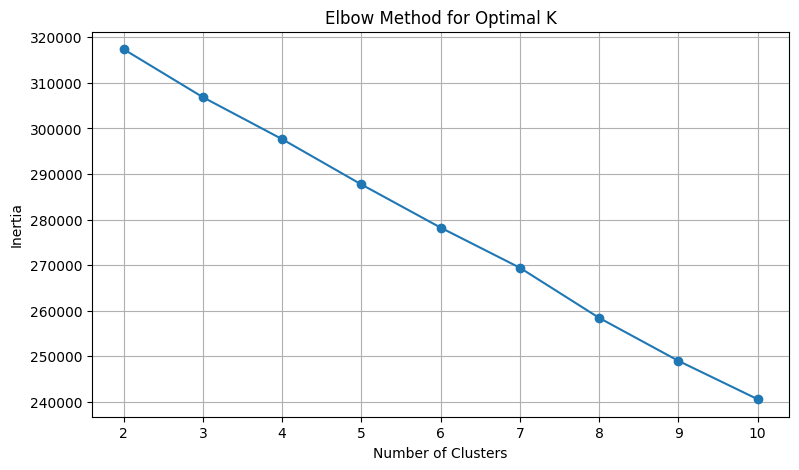

In [147]:

inertia = []

K = range(2, 11)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K, inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)

plt.show()

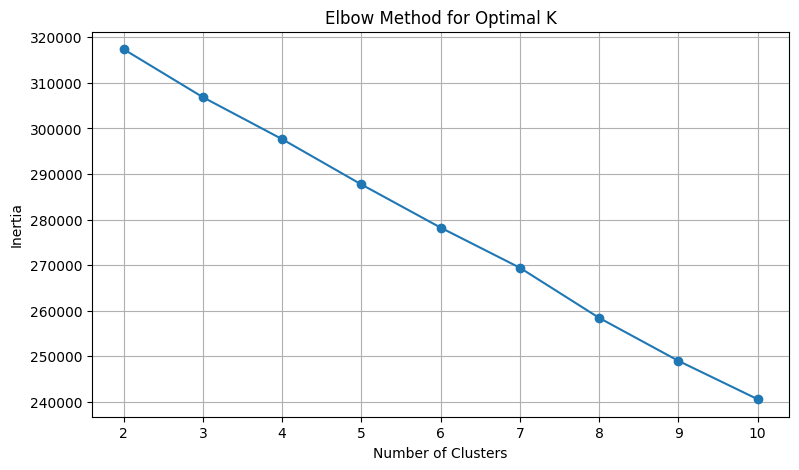

In [148]:

inertia = []

K = range(2, 11)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))

plt.plot(K, inertia, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)

plt.show()

In [149]:


scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    scores.append(score)

    print(f"K={k}, Silhouette Score={score:.4f}")

K=2, Silhouette Score=0.2449
K=3, Silhouette Score=0.2585
K=4, Silhouette Score=0.1319
K=5, Silhouette Score=0.0719
K=6, Silhouette Score=0.2055
K=7, Silhouette Score=0.2299
K=8, Silhouette Score=0.2806
K=9, Silhouette Score=0.3282
K=10, Silhouette Score=0.3248


In [150]:
kmeans = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=10
)

data["cluster"] = kmeans.fit_predict(X_scaled)

data[["title", "type", "release_year", "cluster"]].head(10)

,title,type,release_year,cluster
0,Dick Johnson Is Dead,Movie,2020,3
1,Ganglands,TV Show,2021,7
2,Midnight Mass,TV Show,2021,2
3,Confessions of an Invisible Girl,Movie,2021,4
4,Sankofa,Movie,1993,5
5,The Great British Baking Show,TV Show,2021,2
6,The Starling,Movie,2021,0
7,Motu Patlu in the Game of Zones,Movie,2019,4
8,Je Suis Karl,Movie,2021,5
9,Motu Patlu in Wonderland,Movie,2013,4


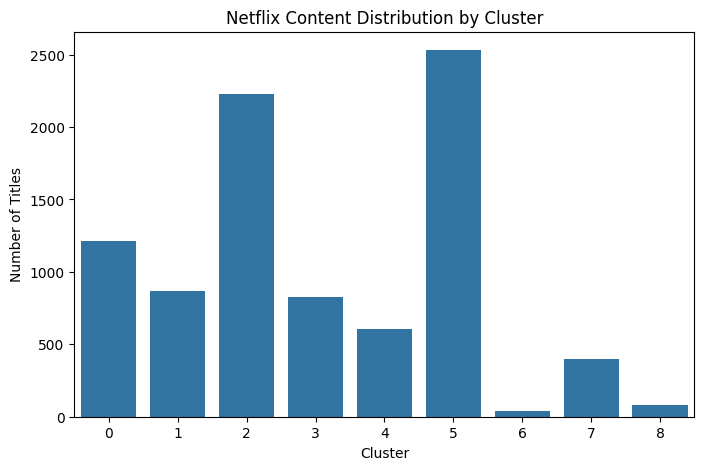

In [151]:


plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="cluster"
)

plt.title("Netflix Content Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")

plt.show()

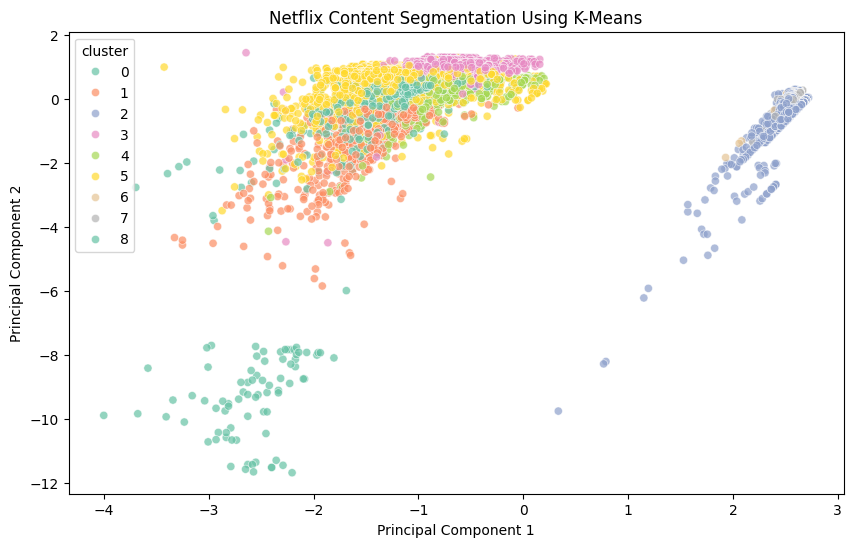

In [152]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

data["PCA1"] = X_pca[:, 0]
data["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x="PCA1",
    y="PCA2",
    hue="cluster",
    palette="Set2",
    s=35,
    alpha=0.7
)

plt.title("Netflix Content Segmentation Using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [153]:
cluster_summary = data.groupby("cluster").agg(
    total_titles=("title", "count"),
    average_release_year=("release_year", "mean"),
    movies=("type", lambda x: (x == "Movie").sum()),
    tv_shows=("type", lambda x: (x == "TV Show").sum())
)

print(cluster_summary)    

         total_titles  average_release_year  movies  tv_shows
cluster                                                      
0                1210           2013.012397    1210         0
1                 871           2009.327210     871         0
2                2226           2016.385445       0      2226
3                 829           2016.225573     829         0
4                 605           2014.076033     605         0
5                2531           2014.485579    2531         0
6                  39           2017.641026       0        39
7                 399           2017.879699       0       399
8                  80           1973.437500      80         0


In [154]:
for cluster in sorted(data["cluster"].unique()):
    print(f"\nCluster {cluster} - Top Genres")

    print(
        data[data["cluster"] == cluster]
        ["primary_genre"]
        .value_counts()
        .head(5)
    )


Cluster 0 - Top Genres
primary_genre
Comedies    1210
Name: count, dtype: int64

Cluster 1 - Top Genres
primary_genre
Action & Adventure    859
Cult Movies            12
Name: count, dtype: int64

Cluster 2 - Top Genres
primary_genre
International TV Shows    773
Kids' TV                  385
British TV Shows          252
Docuseries                220
Anime Series              174
Name: count, dtype: int64

Cluster 3 - Top Genres
primary_genre
Documentaries    829
Name: count, dtype: int64

Cluster 4 - Top Genres
primary_genre
Children & Family Movies    605
Name: count, dtype: int64

Cluster 5 - Top Genres
primary_genre
Dramas                  1599
Stand-Up Comedy          334
Horror Movies            275
International Movies     128
Thrillers                 65
Name: count, dtype: int64

Cluster 6 - Top Genres
primary_genre
TV Action & Adventure    39
Name: count, dtype: int64

Cluster 7 - Top Genres
primary_genre
Crime TV Shows    399
Name: count, dtype: int64

Cluster 8 - Top Genr

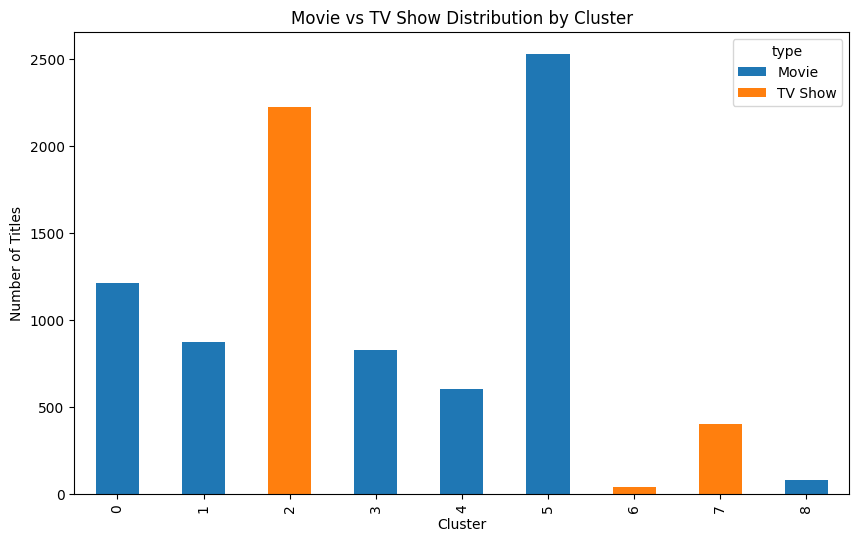

In [155]:
cluster_type = pd.crosstab(
    data["cluster"],
    data["type"]
)

cluster_type.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Movie vs TV Show Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Titles")
plt.show()

In [156]:
import joblib
from pathlib import Path

model_dir = Path(
    "/home/sourabh/learning/Netflix-Content-Segmentation/models"
)

model_dir.mkdir(parents=True, exist_ok=True)

artifacts = {
    "kmeans": kmeans,
    "scaler": scaler,
    "pca": pca,
    "feature_columns": features.columns.tolist()
}

joblib.dump(
    artifacts,
    model_dir / "kmeans_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
